# Figure 5 | SNOWPACK simulations and observations

Publication revision of [the in-review notebook](inreview/figure5.ipynb).
The main figure shows PPSA snow depth and snow water equivalent (SWE) in WY 2025
(October 1–July 1) and HEEN SWE in WY 2020–2022. The second figure retains the SWE-only layout,
including the two pit dates selected in the [all-pit comparison](figuresX_all_snowpits.ipynb). Both use the
lapse-rate-corrected `_soil` simulations and keep the original observations.

In [8]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import pandas as pd
import seaborn as sns
import xarray as xr

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'envs/rasterio.yml').is_file() and (p / 'figures').is_dir())
output_dir = root / 'figures/files'
model_root = Path('/home/cassie/python/models/run_snowpack/sites')
data_root = Path('/hdd/snow_hydrology')

In [9]:
def read_smet_fields(path, fields_to_read):
    header = {}
    with path.open() as source:
        for line in source:
            if line.strip() == '[DATA]':
                break
            if '=' in line:
                key, value = line.split('=', 1)
                header[key.strip()] = value.strip()
        else:
            raise ValueError(f'Missing [DATA] section in {path}')
        fields = header['fields'].split()
        data = pd.read_csv(source, sep=r'\s+', names=fields,
                           usecols=['timestamp', *fields_to_read], index_col='timestamp',
                           parse_dates=['timestamp'], na_values=float(header['nodata']))
    if data.empty or not data.index.is_unique or not data.index.is_monotonic_increasing:
        raise ValueError(f'Expected nonempty, ordered data in {path}')
    multipliers = dict(zip(fields, map(float, header['units_multiplier'].split())))
    return data.mul({field: multipliers[field] for field in fields_to_read})

In [10]:
fields_to_read = ['HS_mod', 'SWE']
styles = {
    'hrrrak_lapserate': ('HRRR-AK Forcing', 'tab:blue'),
    'met_hrrrak_lapserate': ('Met Mixed Forcing', 'tab:green'),
}
windows = {
    'ppsa': ('2024-10-01', '2025-07-01'),
    'heen': ('2019-09-01', '2022-08-30'),
}
simulations = {}
for site, window in windows.items():
    mixed_span = 'WY2020-WY2022' if site == 'heen' else 'WY2020-WY2025'
    simulations[site] = {}
    for forcing in styles:
        span = mixed_span if forcing.startswith('met_') else 'WY2020-WY2025'
        path = model_root / site / 'output' / f'{forcing}_{site}_{span}_soil.smet'
        data = read_smet_fields(path, fields_to_read).loc[window[0]:window[1]].copy()
        # SMET converts depth to m and SWE to kg/m² (equivalent to mm water).
        data['HS_mod'] *= 100
        simulations[site][forcing] = data

met = data_root / 'met_station'
with xr.open_dataset(met / 'ppsa2/pppsa_met_station_data_synoptic_2026-03-20') as ds:
    ppsa_depth = ds['hs'].sel(time=slice(*windows['ppsa'])).to_series()
# Preserve the documented early-season sensor spike exclusion from the review.
ppsa_depth.loc['2024-10-01':'2024-10-15'] = float('nan')
with xr.open_dataset(met / 'snotel/heenlatinee/heen_met_2016_2026_cleaned_v1.nc') as ds:
    heen_swe = ds['swe'].sel(time=slice(*windows['heen'])).to_series() * 10

pits = pd.read_csv(data_root / 'field_data/snow_pit_swe_measurements_WY2025.csv',
                   index_col=0, parse_dates=True).sort_index()
pits = pits.loc[windows['ppsa'][0]:windows['ppsa'][1]]
selected_pit_dates = set(pd.read_csv(root / 'figures/data/ppsa_snowpit_selection_WY2025.csv', parse_dates=['date'])['date'])
if len(selected_pit_dates) != 2 or not selected_pit_dates.issubset(pits.index.normalize()):
    raise ValueError('Expected both selected pit dates in the PPSA plot window.')


In [11]:
def format_month_ticks(ax, *, labels=True, single_year=False):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=None if single_year else [1, 6, 10], bymonthday=1))
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonthday=1))

    def label_date(value, _):
        date = mdates.num2date(value)
        month = 'June' if date.month == 6 else date.strftime('%b')
        return f'1 {month}' if single_year else f'1 {month}\n{date.year}'

    ax.xaxis.set_major_formatter(FuncFormatter(label_date))
    ax.tick_params(axis='x', which='major', bottom=True, labelbottom=labels,
                   length=5, width=0.8, color='#46515b', labelsize=9)
    ax.tick_params(axis='x', which='minor', bottom=True, labelbottom=False,
                   length=3, width=0.7, color='#46515b')

In [12]:
def draw_figure(stem, *, swe_only=False):
    with sns.axes_style('darkgrid'), mpl.rc_context({'font.family': 'DejaVu Sans', 'pdf.fonttype': 42}):
        fig = plt.figure(figsize=(12, 7.4 if swe_only else 10))
        grid = fig.add_gridspec(2 if swe_only else 3, 1, left=0.09, right=0.9,
                               top=0.83 if swe_only else 0.86, bottom=0.09, hspace=0.43)
        if swe_only:
            ppsa_swe = fig.add_subplot(grid[0])
            heen_ax = fig.add_subplot(grid[1], sharey=ppsa_swe)
            panels = [(ppsa_swe, 'ppsa', 'SWE'), (heen_ax, 'heen', 'SWE')]
        else:
            depth_ax = fig.add_subplot(grid[0])
            ppsa_swe = fig.add_subplot(grid[1], sharex=depth_ax)
            heen_ax = fig.add_subplot(grid[2], sharey=ppsa_swe)
            panels = [(depth_ax, 'ppsa', 'HS_mod'), (ppsa_swe, 'ppsa', 'SWE'),
                      (heen_ax, 'heen', 'SWE')]

        ppsa_start, ppsa_end = windows['ppsa']
        field = pits.loc[ppsa_start:ppsa_end]
        swe_peak = max(field['swe_mm'].max(), heen_swe.max())

        for i, (ax, site, var) in enumerate(panels):
            is_depth = var == 'HS_mod'
            start, end = (ppsa_start, ppsa_end) if site == 'ppsa' else windows[site]
            for forcing, frame in simulations[site].items():
                series = frame[var].loc[start:end]
                label, color = styles[forcing]
                ax.plot(series.index, series, color=color, lw=2, label=label)
                if not is_depth:
                    swe_peak = max(swe_peak, series.max())

            if site == 'ppsa':
                for date in field.index:
                    emphasized = date.normalize() in selected_pit_dates
                    ax.axvline(date, color='black' if emphasized else 'grey',
                               linestyle='--', alpha=0.8 if emphasized else 0.32,
                               linewidth=1.3 if emphasized else 0.9)
                values = field['snow_depth_cm' if is_depth else 'swe_mm']
                ax.scatter(values.index, values, color='black',
                           edgecolors='white', linewidth=0.8, s=37, zorder=5,
                           label='Snow Pit Observations')
                name = 'Powder Patch Meteorological Station (PPSA)'
                wy = 'WY 2025'
            else:
                ax.plot(heen_swe.index, heen_swe, color='black', ls='--', lw=1.7,
                        label='SNOTEL Observations')
                name = 'Heen Latinee SNOTEL (HEEN)'
                wy = 'WY 2020–2022'
            if is_depth:
                ax.plot(ppsa_depth.index, ppsa_depth, color='black', ls='--', lw=1.7,
                        label='Met Station Observations')
                depth_max = max(ppsa_depth.max(), field['snow_depth_cm'].max(),
                                *(d['HS_mod'].max() for d in simulations['ppsa'].values()))
                ax.set_ylim(-10, max(275, depth_max + 10))

            ax.set_xlim(pd.Timestamp(start), pd.Timestamp(end))
            ax.set_title(name, loc='left', fontsize=12, weight='normal', pad=16)
            ax.text(0, 1.025, wy, transform=ax.transAxes, ha='left', va='bottom',
                    fontsize=9, color='#45515a')
            ax.text(0.009, 0.96, f'{chr(65 + i)})', transform=ax.transAxes,
                    va='top', fontsize=10, color='dimgrey')
            ax.set_ylabel('snow depth (cm)' if is_depth else 'snow water equivalent (mm)')
            ax.tick_params(axis='y', labelsize=9)
            format_month_ticks(ax, labels=not is_depth, single_year=site == 'ppsa')
            inches = 2.54 if is_depth else 25.4
            secondary = ax.secondary_yaxis(
                'right', functions=(lambda value, scale=inches: value / scale,
                                    lambda value, scale=inches: value * scale)
            )
            secondary.set_ylabel('snow depth (inches)' if is_depth else
                                 'snow water equivalent (inches)')
            secondary.tick_params(labelsize=9)

        ppsa_swe.set_ylim(-50, swe_peak + 140)
        heading = ('SNOWPACK simulations and observed snow water equivalent' if swe_only
                   else 'SNOWPACK simulations and observed snow depth and SWE')
        fig.text(0.09, 0.975, heading, ha='left', va='top', fontsize=16, weight='bold')
        entries = {}
        for ax, _, _ in panels:
            handles, labels = ax.get_legend_handles_labels()
            entries.update(zip(labels, handles))
        fig.legend(entries.values(), entries.keys(), loc='upper left', bbox_to_anchor=(0.09, 0.932),
                   ncols=len(entries), fontsize=9, framealpha=1, borderaxespad=0,
                   facecolor=ppsa_swe.get_facecolor(), edgecolor='#d1d3dc')

        output_dir.mkdir(parents=True, exist_ok=True)
        for extension in ('png', 'pdf'):
            fig.savefig(output_dir / f'{stem}.{extension}', dpi=300, facecolor='white')
        return fig

## Snow depth and SWE

Panels A and B share the PPSA date axis. Panels B and C share SWE limits.

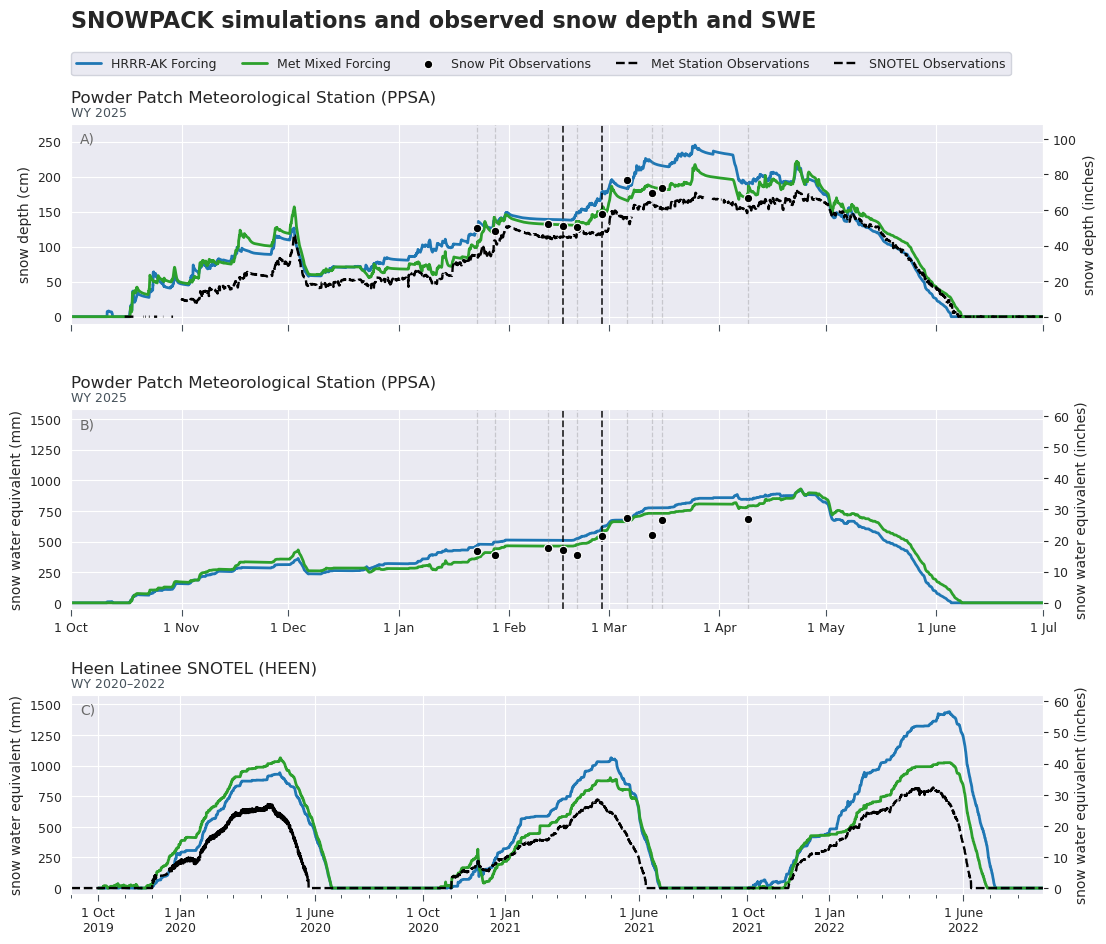

In [13]:
fig = draw_figure('figure5_publication')
plt.show()

## SWE-only comparison

The PPSA panel retains the October–July window and highlights the selected cold and warm pits in black, as in the three-panel figure.

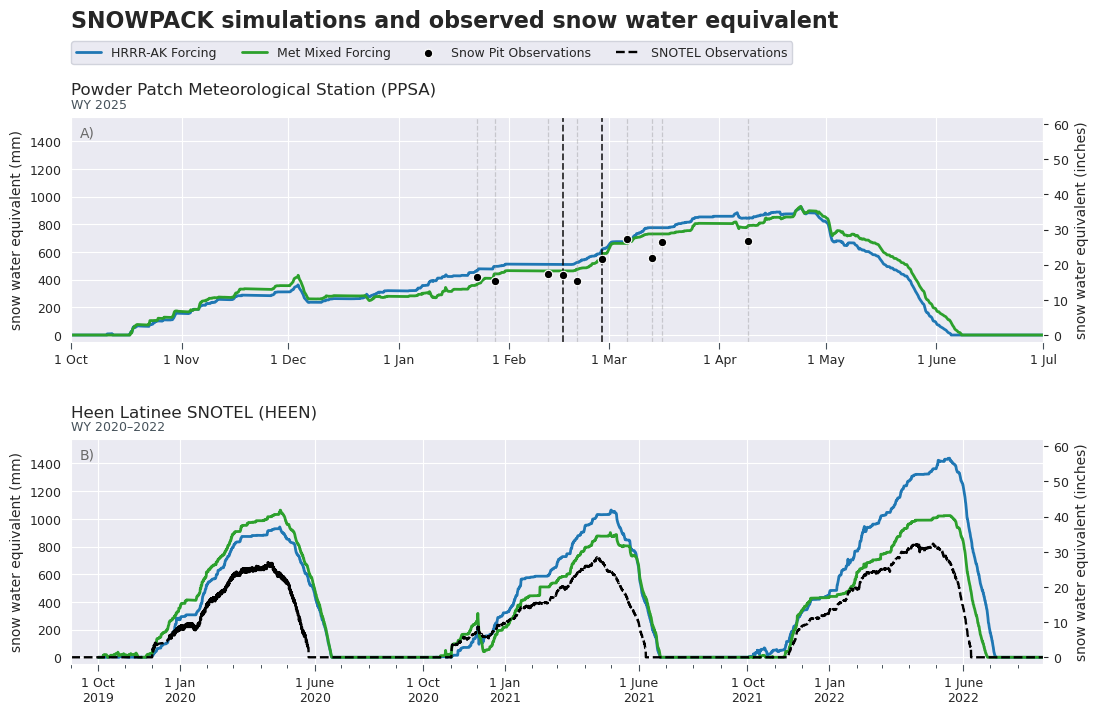

In [14]:
fig = draw_figure('figure5_publication_swe_only', swe_only=True)
plt.show()